#### 데이터 분석 개요 및 기초통계

실전 데이터 분석(DA/DS)에서 “진짜 자주 쓰이는 통계”는 이론 전체가 아니라 의사결정에 직접 쓰이는 핵심 통계
----------------------------
# 1. 기술통계 (Descriptive Statistics) — 제일 중요
# 왜 쓰나?

# 데이터 “감 잡기” 단계 (EDA 시작점)

- 핵심 지표
1. 평균 (mean)
2. 중앙값 (median)
3. 표준편차 (std)
4. 최댓값/최솟값
5. 분위수 (quantiles)


> 인용구 추가



In [63]:
# ============================================
#  라이브러리 불러오기
# ============================================

# 데이터 분석용 라이브러리
import pandas as pd

# 수치 계산용 라이브러리
# (현재 예제에서는 사용되지 않지만
# 향후 평균, 표준편차, 배열 계산 등에 자주 사용)
import numpy as np


# ============================================
#  예제 데이터 생성
# ============================================

# DataFrame 생성
# sales 컬럼에 매출 데이터 저장
df = pd.DataFrame({
    "sales": [100, 120, 130, 90, 150, 300, 110]
})

# 생성된 데이터
#
#   sales
# 0  100
# 1  120
# 2  130
# 3   90
# 4  150
# 5  300  ← 이상치 후보
# 6  110


# ============================================
#  기술통계 확인
# ============================================

# describe()
# 데이터의 기초 통계량을 한 번에 확인
#
# count : 데이터 개수
# mean  : 평균
# std   : 표준편차
# min   : 최소값
# 25%   : 1사분위수(Q1)
# 50%   : 중앙값(Median)
# 75%   : 3사분위수(Q3)
# max   : 최대값
#
# 데이터 분포를 빠르게 파악할 때 사용

df.describe()
df["sales"].mean()


np.float64(142.85714285714286)

In [64]:
df["sales"].median()


120.0

In [65]:
df["sales"].std()


72.0449595077698

In [66]:
# ============================================
# 분위수(Quantile) 계산
# ============================================

# quantile()
# 데이터를 특정 비율로 나누는 값을 계산하는 함수
#
# 0.25 → 1사분위수(Q1)
#         전체 데이터의 하위 25% 지점
#
# 0.50 → 중앙값(Median)
#         전체 데이터의 가운데 값
#
# 0.75 → 3사분위수(Q3)
#         전체 데이터의 상위 75% 지점
#
# 분위수는 데이터 분포와 이상치 탐지(IQR)에 자주 사용됨

df["sales"].quantile([0.25, 0.5, 0.75])

# 예제 데이터
# [100, 120, 130, 90, 150, 300, 110]
#
# 정렬 후
# [90, 100, 110, 120, 130, 150, 300]
#
# 결과 예시
#
# 0.25    105.0
# 0.50    120.0
# 0.75    140.0
#
# 해석
#
# Q1 = 105
# → 데이터의 25%가 이 값 이하에 위치
#
# Median = 120
# → 데이터를 반으로 나누는 기준값
#
# Q3 = 140
# → 데이터의 75%가 이 값 이하에 위치
#
# IQR 계산 시 사용
#
# IQR = Q3 - Q1
#     = 140 - 105
#     = 35
#
# 이후 이상치 범위 계산
#
# 하한 = Q1 - 1.5 × IQR
# 상한 = Q3 + 1.5 × IQR
#
# 실무 활용
# - 이상치 탐지(IQR)
# - 데이터 분포 확인
# - Box Plot 작성
# - 강건한(Robust) 통계 분석
# - 스케일링 전 데이터 점검

df["sales"].quantile([0.25, 0.5, 0.75])

,sales
0.25,105.0
0.50,120.0
0.75,140.0


In [67]:

# ============================================
# 개별 확인
# ============================================

# ============================================
#  이상치 탐지 (Outlier Detection)
# ============================================

# 왜 중요한가?
#
# 머신러닝 모델 성능 저하의 주요 원인
# 평균 왜곡
# 회귀모델 기울기 왜곡
# 군집분석 오류 발생
#
# 따라서 데이터 전처리 단계에서
# 반드시 수행하는 핵심 작업


# ============================================
# IQR(Inter Quartile Range) 방식
# ============================================

# 실무에서 가장 널리 사용되는 이상치 탐지 방법

# --------------------------------------------
# Q1 (1사분위수)
# 데이터의 하위 25% 지점
# --------------------------------------------
Q1 = df["sales"].quantile(0.25)

# 예시 결과
# Q1 ≈ 105


# --------------------------------------------
# Q3 (3사분위수)
# 데이터의 상위 75% 지점
# --------------------------------------------
Q3 = df["sales"].quantile(0.75)

# 예시 결과
# Q3 ≈ 140


# --------------------------------------------
# IQR 계산
# --------------------------------------------

# IQR = Q3 - Q1
#
# 가운데 50% 데이터가 위치하는 범위
#
# 데이터의 퍼짐 정도를 나타냄
IQR = Q3 - Q1

# 예시
# IQR = 140 - 105 = 35


# --------------------------------------------
# 이상치 하한선(Lower Bound)
# --------------------------------------------

# Q1보다 너무 작은 값 탐지
#
# 공식
# Q1 - 1.5 × IQR
lower = Q1 - 1.5 * IQR

# 예시
# 105 - 1.5×35
# = 52.5


# --------------------------------------------
# 이상치 상한선(Upper Bound)
# --------------------------------------------

# Q3보다 너무 큰 값 탐지
#
# 공식
# Q3 + 1.5 × IQR
upper = Q3 + 1.5 * IQR

# 예시
# 140 + 1.5×35
# = 192.5


# ============================================
# 이상치 추출
# ============================================

# 조건1
# sales < lower
#
# 조건2
# sales > upper
#
# 둘 중 하나라도 만족하면 이상치
outliers = df[
    (df["sales"] < lower) |
    (df["sales"] > upper)
]


# ============================================
# 결과 확인
# ============================================

outliers

# 결과
#
#   sales
# 5  300
#
# 300은 상한선 192.5를 초과하므로
# 이상치(Outlier)로 판정


# ============================================
# 실무 Tip
# ============================================

# 이상치 발견 후 처리 방법

# 1. 제거
# df = df[(df["sales"] >= lower) & (df["sales"] <= upper)]

# 2. 상한값으로 치환(Capping)
# df["sales"] = np.where(
#     df["sales"] > upper,
#     upper,
#     df["sales"]
# )

# 3. 로그 변환
# df["sales_log"] = np.log1p(df["sales"])

# 4. 원인 조사 후 유지
# (실제 이벤트, 프로모션, 블랙프라이데이 등)

,sales
5,300


In [68]:
# ============================================
# Z-score 방식 이상치 탐지
# ============================================

# scipy.stats의 zscore 함수 가져오기
#
# Z-score:
# 각 데이터가 평균으로부터
# 몇 표준편차(Standard Deviation) 떨어져 있는지 계산
#
# 공식:
#
# Z = (X - 평균) / 표준편차
#
# 장점
# - 통계학에서 널리 사용
# - 데이터의 상대적 위치 파악 가능
#
# 단점
# - 이상치가 평균과 표준편차를 왜곡할 수 있음
# - 데이터가 정규분포에 가까울 때 효과적

from scipy.stats import zscore


# ============================================
# Z-score 계산
# ============================================

# sales 컬럼의 모든 값에 대해
# Z-score 계산 후 z 컬럼 생성

df["z"] = zscore(df["sales"])

# 예시 결과
#
# sales      z
# ----------------
# 100    -0.56
# 120    -0.27
# 130    -0.13
# 90     -0.70
# 150     0.16
# 300     2.43
# 110    -0.42
#
# 의미
#
# z = 0
# → 평균과 동일
#
# z = 1
# → 평균보다 1 표준편차 큼
#
# z = -1
# → 평균보다 1 표준편차 작음


# ============================================
# 이상치 추출
# ============================================

# abs()
# 절대값 사용
#
# +2 또는 -2 모두 이상치로 보기 위함
#
# 기준:
#
# |z| > 2
# → 평균에서 2표준편차 이상 떨어짐
#
# |z| > 3
# → 더 엄격한 기준
#
# 실무에서는
# |z| > 2 또는 |z| > 3 사용

df[df["z"].abs() > 2]

# 결과
#
#   sales     z
# 5  300   2.43
#
# 300은 평균으로부터
# 약 2.43 표준편차 떨어져 있으므로
# 이상치로 판정

,sales,z
5,300,2.355941


In [69]:
# ============================================
#  분포 확인 (Distribution Check)
# ============================================

# 왜 사용하는가?
#
# 머신러닝/통계분석 전에
# 데이터가 어떤 형태로 분포하는지 확인하기 위함
#
# 확인하는 대표 지표
#
# 1. 왜도(Skewness)
#    → 분포가 한쪽으로 치우쳤는가?
#
# 2. 첨도(Kurtosis)
#    → 극단값(이상치)이 많은가?
#
# 데이터가 심하게 왜곡되어 있으면
#
# - 평균이 대표값 역할을 못함
# - 회귀모델 성능 저하
# - 정규성 가정 위반
#
# 따라서 로그변환(Log Transform),
# 표준화(Standardization) 등을 고려


# ============================================
# 왜도(Skewness)
# ============================================

# skew()
#
# 데이터 분포의 비대칭 정도 측정
#
# 기준
#
# skew = 0
# → 완전 대칭 (정규분포)
#
# skew > 0
# → 오른쪽 꼬리가 김
# → 큰 값들이 존재
#
# skew < 0
# → 왼쪽 꼬리가 김
# → 작은 값들이 존재

df["sales"].skew()

# 현재 데이터
#
# [100,120,130,90,150,300,110]
#
# 300이 존재하므로
# 오른쪽으로 긴 꼬리 발생
#
# 결과 예시
#
# 2.3 근처
#
# 해석
#
# 강한 양의 왜도
# (Right Skewed Distribution)
#
# 즉,
# 대부분은 작은 값인데
# 일부 큰 값(300)이 존재


# ============================================
# 첨도(Kurtosis)
# ============================================

# kurt()
#
# 분포의 뾰족한 정도
# 극단값(Outlier)의 존재 정도 측정
#
# Pandas는 Fisher 방식 사용
#
# 기준
#
# kurt = 0
# → 정규분포 수준
#
# kurt > 0
# → 극단값 많음
# → 꼬리가 두꺼움
#
# kurt < 0
# → 극단값 적음
# → 분포가 평평함

df["sales"].kurt()

# 현재 데이터
#
# 300이라는 큰 값 존재
#
# 결과 예시
#
# 약 5 ~ 6
#
# 해석
#
# 정규분포보다 훨씬 뾰족
#
# 이상치 영향이 큼
#
# 극단값 존재 가능성 매우 높음

np.float64(5.381684370002526)

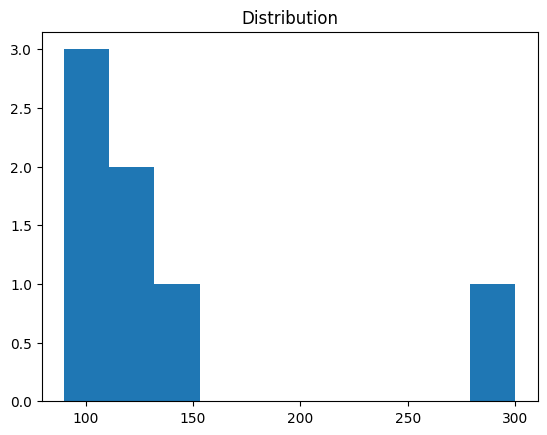

In [70]:
# ============================================
# 히스토그램(Histogram) 시각화
# ============================================

# 시각화 라이브러리
import matplotlib.pyplot as plt

# sales 데이터의 분포를 히스토그램으로 표현
#
# bins=10
# → 데이터를 10개 구간으로 나누어 빈도수 표시
#
# x축 : sales 값
# y축 : 해당 구간의 데이터 개수

plt.hist(df["sales"], bins=10)

# 그래프 제목 설정
plt.title("Distribution")

# 그래프 출력
plt.show()

# 해석
#
# 대부분 데이터는
# 90~150 구간에 몰려 있음
#
# 300은 멀리 떨어져 있어
# 이상치(Outlier) 후보임을 시각적으로 확인 가능

In [71]:
# ============================================
# 상관관계 분석용 데이터 생성
# ============================================

df = pd.DataFrame({
    "ads": [1,2,3,4,5],
    "sales": [2,4,5,4,5],
    "price": [10,9,8,7,6]
})

# 데이터
#
# ads   sales   price
# -------------------
# 1       2      10
# 2       4       9
# 3       5       8
# 4       4       7
# 5       5       6

In [72]:
# ============================================
# 상관계수(Correlation Coefficient)
# ============================================

# corr()
#
# 숫자형 컬럼들 간의 상관관계 계산
#
# 기본값:
# Pearson Correlation
#
# 범위
#
# -1 ~ +1
#
# +1
# → 완전한 양의 상관관계
#
# 0
# → 상관관계 없음
#
# -1
# → 완전한 음의 상관관계

df.corr()

,ads,sales,price
ads,1.000000,0.774597,-1.000000
sales,0.774597,1.000000,-0.774597
price,-1.000000,-0.774597,1.000000


In [73]:
# 실무에서 왜 중요한가?
# 1. Feature Selection
X = df[["ads", "price"]]

# 상관관계 해석
ads ↔ sales

약:

r≈0.77

강한 양의 상관관계
광고가 증가할수록 매출 증가 경향
price ↔ sales

약:

r≈−0.77

강한 음의 상관관계
가격이 낮아질수록 매출 증가 경향
ads ↔ price

r=−1.0

완전한 음의 상관관계
광고 증가와 가격 감소가 정확히 반대로 움직임

In [74]:
# 2. 다중공선성(Multicollinearity) 확인

"""
# 예를 들어:
ads
marketing_budget
promotion_cost

#이 변수들이 서로 상관계수 0.95 이상이면

#정보가 중복됨
#회귀모델 불안정
#계수 해석 어려움
"""

'\n# 예를 들어:\nads\nmarketing_budget\npromotion_cost\n\n#이 변수들이 서로 상관계수 0.95 이상이면\n\n#정보가 중복됨\n#회귀모델 불안정\n#계수 해석 어려움\n'

In [75]:
#3. 타깃 변수와의 관계 파악
df.corr()["sales"]

"""
결과 예시:

ads      0.77
sales    1.00
price   -0.77

즉,

ads → 중요 변수
price → 중요 변수

라고 판단할 수 있습니다.
"""

'\n결과 예시:\n\nads      0.77\nsales    1.00\nprice   -0.77\n\n즉,\n\nads → 중요 변수\nprice → 중요 변수\n\n라고 판단할 수 있습니다.\n'

,ads,sales,price
ads,1.000000,0.774597,-1.000000
sales,0.774597,1.000000,-0.774597
price,-1.000000,-0.774597,1.000000


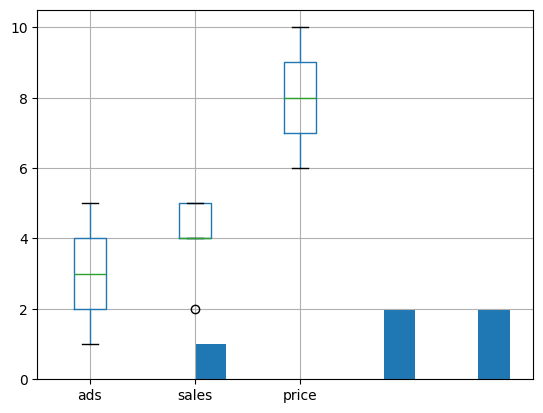

In [76]:
#실무 EDA에서 가장 많이 쓰는 흐름
# 기초 통계
df.describe()

# 결측치 확인
df.isnull().sum()

# 이상치 확인
df.boxplot()

# 분포 확인
df["sales"].hist()

# 왜도/첨도
df["sales"].skew()
df["sales"].kurt()

# 상관관계
df.corr()

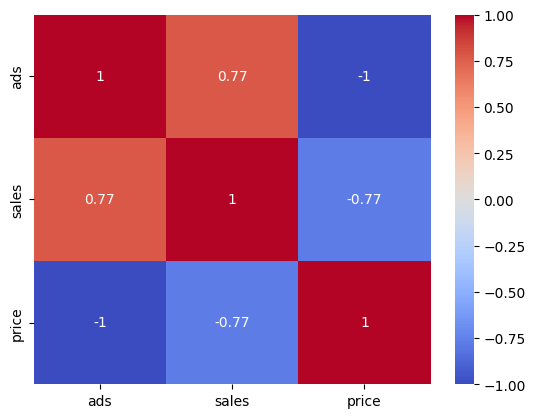

In [77]:
# ==================================================
# 시각화 (Correlation Heatmap)
# ==================================================
# 목적:
# 상관계수(Correlation Coefficient)를 색상으로 표현하여
# 변수 간 관계를 한눈에 파악하기 위함
#
# 왜 사용하는가?
# 숫자로 된 상관계수 표는 직관적으로 보기 어려움
# Heatmap은 색상으로 강도를 표현하여
# 관계가 강한 변수와 약한 변수를 쉽게 찾을 수 있음
#
# 실무 활용:
# - Feature Selection(변수 선택)
# - 다중공선성(Multicol선성) 확인
# - 변수 간 관계 탐색(EDA)
#
# 해석 방법:
# +1 에 가까울수록 → 강한 양의 상관관계
# -1 에 가까울수록 → 강한 음의 상관관계
#  0 에 가까울수록 → 관계 없음
#
# 예시:
# 광고비 ↑ → 매출 ↑  => 양의 상관관계
# 가격 ↑ → 판매량 ↓ => 음의 상관관계
#
# 주의:
# 상관관계가 높다고 인과관계가 성립하는 것은 아님
# (Correlation ≠ Causation)
#
# 일반적인 기준
# |r| >= 0.7 : 강한 상관관계
# 0.3 <= |r| < 0.7 : 중간 상관관계
# |r| < 0.3 : 약한 상관관계
# ==================================================

import seaborn as sns

# df.corr()
# 데이터프레임의 수치형 변수들 간 상관계수 계산
# 기본적으로 Pearson Correlation 사용
corr_matrix = df.corr()

# heatmap()
# 상관계수를 색상으로 시각화
sns.heatmap(
    corr_matrix,      # 상관계수 행렬
    annot=True,       # 각 셀에 상관계수 값 표시
    cmap="coolwarm"   # 양수=빨강, 음수=파랑 계열 색상
)

# 그래프 출력
plt.show()

- 데이터분석 면접 포인트

- 면접에서 자주 나오는 질문:

- Heatmap을 왜 사용하는가?

- 답변: 변수 간 관계를 시각적으로 파악하기 쉽다.
다중공선성을 확인할 수 있다.
모델 학습 전에 불필요한 변수를 제거하는 데 활용할 수 있다.

# p-value란?

가장 중요한 통계 개념 중 하나

의미:

"현재 관측된 차이가 우연히 발생할 확률"

예시:

p-value = 0.03

→ 3% 확률로 우연히 발생

→ 충분히 작으므로 실제 차이가 있다고 판단

In [78]:
# ==================================================
# 5. 가설검정 (Hypothesis Testing)
# ==================================================

# 실무 사용
# A/B 테스트
# 마케팅 효과 분석

# --------------------------------------------------
# 가설검정이란?
# --------------------------------------------------
# 데이터를 이용하여 특정 주장(가설)이
# 통계적으로 타당한지 판단하는 방법
#
# 예시
# "새 광고가 기존 광고보다 매출을 증가시킨다"
#
# 귀무가설(H0)
# → 두 집단의 평균 차이가 없다.
#
# 대립가설(H1)
# → 두 집단의 평균 차이가 있다.
#
# --------------------------------------------------
# t-test (가장 많이 씀)
# --------------------------------------------------
# 두 집단 평균 차이가 우연인지
# 실제 차이인지 검정하는 방법
#
# 사용 예시
# - 광고 A vs 광고 B
# - 기존 웹페이지 vs 개선 웹페이지
# - 남성 그룹 vs 여성 그룹
# - 치료 전 vs 치료 후
#
# 조건
# 1. 데이터가 연속형이어야 함
# 2. 표본이 독립적이어야 함
# 3. 정규분포를 따른다고 가정
# --------------------------------------------------

from scipy.stats import ttest_ind
import numpy as np

# --------------------------------------------------
# 가상 데이터 생성
# --------------------------------------------------
# 평균 100, 표준편차 10
# 표본 개수 50개
group_A = np.random.normal(100, 10, 50)

# 평균 105, 표준편차 10
# A보다 평균이 5 높음
group_B = np.random.normal(105, 10, 50)

# --------------------------------------------------
# 독립표본 t-test 수행
# --------------------------------------------------
# 두 그룹 평균 차이가
# 통계적으로 유의한지 확인
#
# 반환값
# t_stat  : t 통계량
# p_value : 유의확률(p-value)
# --------------------------------------------------
t_stat, p_value = ttest_ind(group_A, group_B)

# 결과 출력
print("t-stat:", t_stat)
print("p-value:", p_value)

# --------------------------------------------------
# p-value 해석
# --------------------------------------------------
# 일반적으로 α = 0.05 사용
#
# p-value < 0.05
# → 귀무가설 기각
# → 두 집단 평균 차이가 통계적으로 유의함
#
# p-value >= 0.05
# → 귀무가설 채택(정확히는 기각 실패)
# → 차이가 있다고 보기 어려움
# --------------------------------------------------

if p_value < 0.05:
    print("통계적으로 유의한 차이가 있음")
else:
    print("통계적으로 유의한 차이가 없음")

t-stat: -3.3101928578037496
p-value: 0.0013056228368895533
통계적으로 유의한 차이가 있음


면접 단골 질문

Q. p-value가 0.05보다 작으면 무엇을 의미하나요?

답변:

귀무가설이 참이라고 가정했을 때 현재 관측된 결과가 우연히 나타날 확률이 5% 미만이라는 의미이며, 일반적으로 통계적으로 유의한 차이가 있다고 판단한다.

Q. t-test는 언제 사용하나요?

답변:

두 집단 평균의 차이가 통계적으로 유의한지 검정할 때 사용한다. A/B 테스트, 마케팅 성과 비교, 실험군·대조군 비교 등에 가장 많이 활용된다.

- 기초통계에서 가장 중요한 단원 중 하나라서 다음에 배우게 될 ANOVA(분산분석), 카이제곱 검정, 회귀분석의 p-value 해석과도 직접 연결된다.

# 정규분포(Normal Distribution)

1. 통계학에서 가장 중요한 분포

2. 특징:

평균을 중심으로 좌우 대칭
종(Bell) 모양
평균, 중앙값, 최빈값이 같음

3. 68-95-99.7 법칙

정규분포에서는

평균 ± 1σ → 약 68%
평균 ± 2σ → 약 95%
평균 ± 3σ → 약 99.7%  의 데이터가 포함된다.

예)

평균 매출 = 100

표준편차 = 10   이라면

- 90 ~ 110 → 약 68%
- 80 ~ 120 → 약 95%
- 70 ~ 130 → 약 99.7%

In [79]:
# ==================================================
# 6. 확률분포 (Normality Check)
# ==================================================

# 왜 중요?
# 회귀/통계 모델 가정

# --------------------------------------------------
# 정규성 검정(Normality Test)이란?
# --------------------------------------------------
# 데이터가 정규분포(Normal Distribution)를
# 따르는지 확인하는 통계적 검정
#
# 많은 통계 기법들은
# "데이터가 정규분포를 따른다"는
# 가정을 기반으로 만들어짐
#
# 예시
# - t-test
# - ANOVA(분산분석)
# - 선형회귀
# - 일부 머신러닝 알고리즘
#
# 따라서 분석 전에
# 데이터가 정규분포를 따르는지 확인하는 과정이 필요
# --------------------------------------------------

from scipy.stats import normaltest

# --------------------------------------------------
# df["sales"]
# 분석 대상 변수
#
# 예:
# 매출(sales)
# 고객 수(customer_count)
# 광고비(ad_cost)
# --------------------------------------------------

# --------------------------------------------------
# normaltest()
# D'Agostino-Pearson 정규성 검정
#
# 반환값
# stat : 검정 통계량
# p    : p-value
#
# 귀무가설(H0)
# → 데이터는 정규분포를 따른다.
#
# 대립가설(H1)
# → 데이터는 정규분포를 따르지 않는다.
# --------------------------------------------------

stat, p = normaltest(df["sales"])

# 결과 출력
print("p-value:", p)

# --------------------------------------------------
# 결과 해석
# --------------------------------------------------
# p-value >= 0.05
# → 귀무가설 기각 실패
# → 정규분포라고 볼 수 있음
#
# p-value < 0.05
# → 귀무가설 기각
# → 정규분포가 아님
# --------------------------------------------------

if p >= 0.05:
    print("정규분포를 따른다고 볼 수 있음")
else:
    print("정규분포를 따르지 않음")

p-value: nan
정규분포를 따르지 않음


/tmp/ipykernel_2022/311420576.py:55: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  stat, p = normaltest(df["sales"])


# p-value 해석
- 귀무가설(H₀) : 데이터는 정규분포를 따른다.

- 대립가설(H₁) : 데이터는 정규분포를 따르지 않는다.

1. 예시:

p-value = 0.21

→ 0.05보다 큼

→ 정규분포라고 볼 수 있음

2. 예시:

p-value = 0.0003

→ 0.05보다 작음

→ 정규분포가 아님

- 실무 활용
1. 회귀분석 전
normaltest(df["sales"])

매출 데이터가 정규성을 만족하는지 확인

2. A/B 테스트 전
normaltest(group_A)
normaltest(group_B)

t-test 사용 가능 여부 판단

3. 이상치 탐지 : 정규분포가 크게 깨지는 경우

- 데이터 입력 오류
- 극단값(Outlier)
- 데이터 수집 문제 를 의심할 수 있음

4. 면접 단골 질문

Q. 정규성 검정을 왜 하나요?

답변:

많은 통계 기법(t-test, ANOVA, 회귀분석 등)은 데이터가 정규분포를 따른다는 가정을 사용하므로, 분석 전에 정규성 여부를 확인하기 위해 수행한다.

Q. p-value가 0.05보다 작으면?

답변:

귀무가설을 기각하며 데이터가 정규분포를 따르지 않는다고 판단한다.

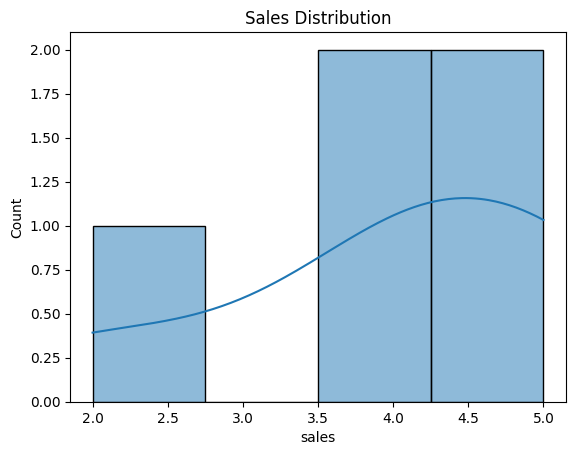

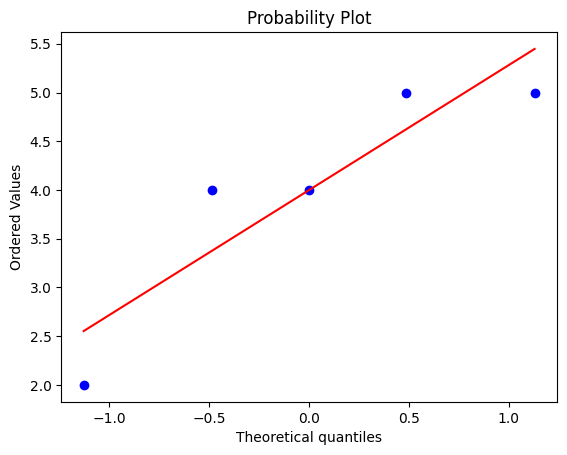

In [80]:
# 데이터분석 실무 팁

# 실무에서는 정규성 검정을 수치로만 판단하지 않고 시각화도 함께 수행한다.

import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df["sales"], kde=True)
plt.title("Sales Distribution")
plt.show()

# 또는

from scipy.stats import probplot

probplot(df["sales"], plot=plt)
plt.show()

# 이렇게 히스토그램 + Q-Q Plot + 정규성 검정(p-value) 를 함께 확인하는 것이 가장 일반적인 분석 방법

In [81]:
# ==================================================
# 7. 범주형 분석 (Categorical Statistics)
# ==================================================

# 실무 핵심
# count
# 비율
# groupby

# --------------------------------------------------
# 범주형 데이터(Categorical Data)란?
# --------------------------------------------------
# 숫자의 크기보다 "분류"가 중요한 데이터
#
# 예시
# 성별 : 남, 여
# 지역 : 서울, 부산, 대구
# 상품등급 : A, B, C
# 고객등급 : VIP, Gold, Silver
#
# 데이터 분석에서 매우 자주 등장하며
# EDA(탐색적 데이터 분석)의 기본 단계
# --------------------------------------------------

import pandas as pd

# --------------------------------------------------
# 예제 데이터 생성
# --------------------------------------------------
# category : 상품 분류
# sales    : 매출
# --------------------------------------------------

df = pd.DataFrame({
    "category": ["A","A","B","B","B","C"],
    "sales": [100,120,80,90,110,70]
})

# ==================================================
# 1. 빈도수(Count) 및 비율 확인
# ==================================================

# --------------------------------------------------
# value_counts()
# 각 범주가 몇 번 등장하는지 계산
# --------------------------------------------------

print(df["category"].value_counts())

# 결과 예시
# B    3
# A    2
# C    1

# --------------------------------------------------
# normalize=True
# 전체 대비 비율 계산
# --------------------------------------------------

print(df["category"].value_counts(normalize=True))

# 결과 예시
# B    0.50
# A    0.33
# C    0.17

# 해석
# B 상품이 전체의 50%
# A 상품이 전체의 33%
# C 상품이 전체의 17%

# ==================================================
# 2. 그룹 통계(Group Statistics)
# ==================================================

# --------------------------------------------------
# groupby()
# 범주별로 데이터를 묶어서 통계 계산
# --------------------------------------------------

category_mean = df.groupby("category")["sales"].mean()

print(category_mean)

# 결과 예시
# A    110
# B     93.33
# C     70

# 계산 과정
#
# A = (100 + 120) / 2 = 110
#
# B = (80 + 90 + 110) / 3
#   = 93.33
#
# C = 70

# --------------------------------------------------
# 의미
# --------------------------------------------------
# 각 카테고리의 평균 매출 확인
#
# 어떤 상품군이
# 가장 높은 매출을 기록하는지 파악 가능

category
B    3
A    2
C    1
Name: count, dtype: int64
category
B    0.500000
A    0.333333
C    0.166667
Name: proportion, dtype: float64
category
A    110.000000
B     93.333333
C     70.000000
Name: sales, dtype: float64


기초통계 핵심

범주형 분석에서 가장 많이 보는 통계량

빈도(Frequency)

각 범주가 몇 번 나타났는지

예)

Category	Count
A	2
B	3
C	1
상대도수(Relative Frequency)

전체 대비 비율

공식:

Relative Frequency=
Total Count
Category Count
	​


예)

B 비율

6
3
	​

=0.5=50%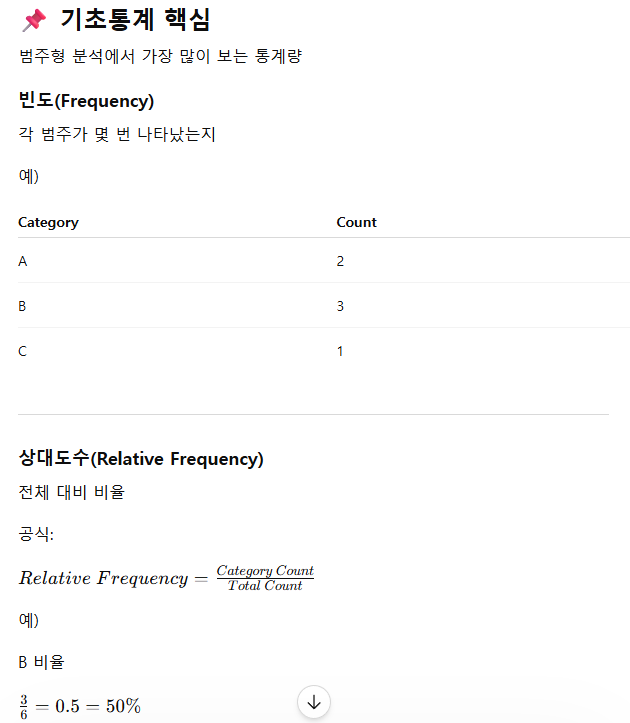

# groupby()가 중요한 이유

# 데이터 분석 실무에서 가장 많이 사용하는 함수 중 하나

# 예시:

df.groupby("gender")["salary"].mean()    # → 성별 평균 연봉

df.groupby("region")["sales"].sum()   # → 지역별 총 매출

df.groupby("product")["profit"].mean()  # → 제품별 평균 수익

In [82]:
#실행 가능한 실무 예제 ① 광고 채널 분석
import pandas as pd

df = pd.DataFrame({
    "channel": ["Google","Google","Naver",
                "Facebook","Naver","Google"],
    "sales": [120,150,130,90,140,160]
})

df.groupby("channel")["sales"].mean()

,sales
channel,
Facebook,90.000000
Google,143.333333
Naver,135.000000


In [83]:
# 실행 가능한 실무 예제 ② 고객 등급 분석
import pandas as pd

df = pd.DataFrame({
    "customer_type": ["VIP","VIP",
                      "Gold","Gold",
                      "Silver","Silver"],
    "purchase": [500,450,300,320,150,180]
})

df.groupby("customer_type")["purchase"].mean()

,purchase
customer_type,
Gold,310.0
Silver,165.0
VIP,475.0


In [84]:
# 실행 가능한 실무 예제 ③ 지역별 매출 분석
import pandas as pd

df = pd.DataFrame({
    "region": ["서울","서울","부산",
               "부산","대구","서울"],
    "revenue": [1000,1200,800,900,700,1300]
})

df.groupby("region")["revenue"].sum()

,revenue
region,
대구,700
부산,1700
서울,3500


In [85]:
# ==================================================
# 8. 핵심 실무 요약
# ==================================================

# --------------------------------------------------
# 실제 분석에서 90%는 이거야
# --------------------------------------------------
# 데이터 분석가, 데이터 사이언티스트,
# 머신러닝 엔지니어가 가장 많이 사용하는
# 통계 기법들
#
# 고급 통계 기법도 중요하지만
# 실무에서는 아래 핵심 통계를 반복적으로 사용
# --------------------------------------------------

# ==================================================
# 필수 TOP 6
# ==================================================

# 1. 평균(mean)
# 데이터의 중심 위치 파악

# 2. 중앙값(median)
# 이상치 영향을 줄인 대표값

# 3. 표준편차(std)
# 데이터의 퍼짐 정도

# 4. 사분위수(quantile)
# 이상치 탐지(IQR)

# 5. 상관관계(correlation)
# 변수 간 관계 분석

# 6. 분포(distribution)
# 정규성, 왜도(skewness), 첨도(kurtosis)

# 7. t-test (A/B Test)
# 두 그룹 평균 차이 검정

# 8. groupby analysis
# 범주별 통계 분석

# ==================================================
# 실무 분석 흐름
# ==================================================

# 1. 데이터 확인
# 데이터 구조 파악
df.describe()

# --------------------------------------------------
# 확인 항목
# count : 데이터 개수
# mean  : 평균
# std   : 표준편차
# min/max : 범위
# --------------------------------------------------

# 2. 결측치 처리
# Missing Value 처리

# 예시
# df.isnull().sum()

# --------------------------------------------------
# 결측치는
# - 삭제(drop)
# - 평균 대체(mean)
# - 중앙값 대체(median)
# 등으로 처리
# --------------------------------------------------

# 3. 이상치 제거
# IQR 또는 Z-score 활용

# 목적
# 모델 성능 향상
# 왜곡된 통계값 방지

# --------------------------------------------------
# 대표 기법
# IQR Method
# Z-score Method
# --------------------------------------------------

# 4. 분포 분석

# 확인 항목
# 히스토그램
# 왜도(Skewness)
# 첨도(Kurtosis)
# 정규성 검정

# 목적
# 데이터 특성 이해
# 통계모델 가정 확인

# 5. 변수 간 상관관계

# corr()
# heatmap()

# 목적
# 변수 선택
# 다중공선성 확인

# 6. 그룹 비교 (A/B Test)

# t-test

# 목적
# 정책 변경 효과 검정
# 마케팅 효과 분석
# 실험 결과 검증

# 7. Feature Engineering

# --------------------------------------------------
# 머신러닝 성능을 높이기 위해
# 새로운 변수를 생성하는 과정
# --------------------------------------------------

# 예시
# 나이 → 연령대
# 날짜 → 요일
# 구매금액 → VIP 여부

# ==================================================
# 데이터 분석 실무 핵심
# ==================================================

# 실전 데이터 분석은
# 통계 전체를 사용하는 것이 아니다.
#
# 평균
# 중앙값
# 표준편차
# 사분위수
# 상관관계
# 분포분석
# t-test
# groupby
#
# 이 핵심 통계를 반복적으로 사용한다.
#
# 따라서 기초통계를 완벽하게 이해하는 것이
# 데이터 분석 역량의 핵심이다.

print("실전 데이터 분석은 통계 전체가 아니라, 6~7개의 핵심 통계 반복이다.")

실전 데이터 분석은 통계 전체가 아니라, 6~7개의 핵심 통계 반복이다.


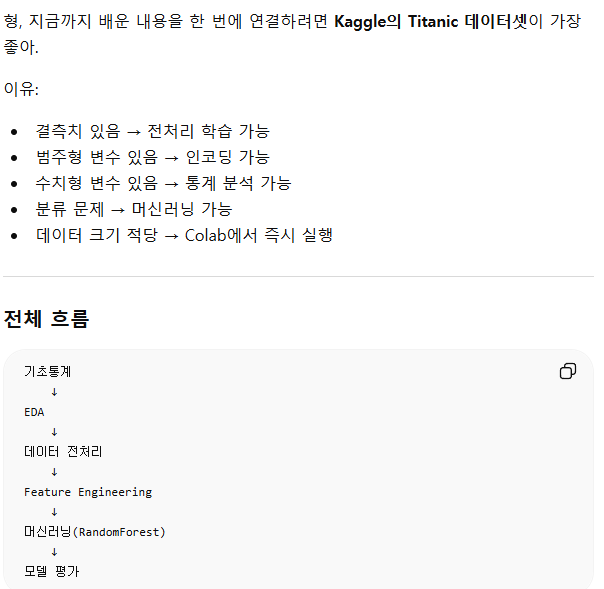

# Titanic 실무 프로젝트 (초상세 강의 교안)
# PART 1. 환경설정 + 데이터 로드 + 기초통계

In [86]:
# ============================================================
# Titanic 생존자 예측 프로젝트
# PART 1
# 환경설정 + 데이터 로드 + 기초통계
# ============================================================

# ============================================================
#  Kaggle API 설치
# ============================================================
#
# Kaggle은 전 세계 데이터 분석가와 머신러닝 엔지니어가
# 가장 많이 사용하는 데이터 공유 플랫폼이다.
#
# Titanic 데이터셋은 데이터 분석 입문자가
# 가장 먼저 접하는 대표적인 실습 데이터이다.
#
# 이 코드는 Kaggle 데이터를 Colab으로
# 다운로드하기 위한 준비 과정이다.
#
# ============================================================

!pip install -q kaggle

In [87]:
# ============================================================
# Titanic 데이터셋 로드
# ============================================================
#
# 공개 GitHub 저장소의 CSV 파일을
# 직접 읽어오는 방법
#
# 별도 다운로드 불필요
# Kaggle API 불필요
#
# Colab에서 즉시 실행 가능
#
# ============================================================

import pandas as pd

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [88]:
# ============================================================
#  데이터 크기 확인
# ============================================================
#
# shape
#
# (행 개수, 열 개수)
#
# Titanic 데이터는
# 약 891명의 승객 정보를 포함한다.
#
# ============================================================

print("데이터 크기 :", df.shape)

데이터 크기 : (891, 12)


In [89]:
# ============================================================
#  컬럼 확인
# ============================================================
#
# columns
#
# 어떤 변수들이 존재하는지 확인
#
# 데이터 분석의 첫 단계
#
# ============================================================

print(df.columns)

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


In [90]:
# ============================================================
#  데이터 구조 확인
# ============================================================
#
# info()
#
# 데이터 분석에서 매우 중요
#
# 확인 가능 정보
#
# - 데이터 개수
# - 데이터 타입
# - 결측치 여부
#
# ============================================================

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [91]:
# ============================================================
# Titanic 컬럼 설명
# ============================================================
#
# PassengerId
# 승객 번호
#
# Survived
# 생존 여부
#
# 0 = 사망
# 1 = 생존
#
# 머신러닝에서 예측할 Target 변수
#
# Pclass
# 객실 등급
#
# 1 = 1등석
# 2 = 2등석
# 3 = 3등석
#
# Name
# 승객 이름
#
# Sex
# 성별
#
# Age
# 나이
#
# SibSp
# 형제/배우자 수
#
# Parch
# 부모/자녀 수
#
# Ticket
# 티켓 번호
#
# Fare
# 운임 요금
#
# Cabin
# 객실 번호
#
# Embarked
# 승선 항구
#
# C = Cherbourg
# Q = Queenstown
# S = Southampton
#
# ============================================================

In [92]:
# ============================================================
#  기초통계 확인
# ============================================================
#
# describe()
#
# 데이터 분석의 시작
#
# 수치형 변수들의
# 대표 통계량 제공
#
# ============================================================

df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [93]:
# ============================================================
# describe() 결과 해석
# ============================================================
#
# count
# 데이터 개수
#
# mean
# 평균
#
# std
# 표준편차
#
# min
# 최소값
#
# 25%
# 1사분위수(Q1)
#
# 50%
# 중앙값(Median)
#
# 75%
# 3사분위수(Q3)
#
# max
# 최대값
#
# ============================================================

In [94]:
# ============================================================
# 평균 (Mean)
# ============================================================
#
# mean()
#
# 데이터의 중심 위치
#
# 가장 많이 사용하는 통계량
#
# ============================================================

print(
    "평균 나이:",
    df["Age"].mean()
)

평균 나이: 29.69911764705882


In [95]:
# ============================================================
# 중앙값 (Median)
# ============================================================
#
# median()
#
# 이상치 영향이 적음
#
# 실무에서는 평균보다
# 중앙값을 더 신뢰하는 경우도 많음
#
# ============================================================

print(
    "중앙값 나이:",
    df["Age"].median()
)

중앙값 나이: 28.0


In [96]:
# ============================================================
# 최빈값 (Mode)
# ============================================================
#
# mode()
#
# 가장 많이 등장한 값
#
# 범주형 데이터 분석에서 자주 사용
#
# ============================================================

print(
    "최빈 승선항:",
    df["Embarked"].mode()[0]
)

최빈 승선항: S


In [97]:
# ============================================================
# 표준편차 (Standard Deviation)
# ============================================================
#
# std()
#
# 데이터 흩어진 정도
#
# 값이 클수록
# 데이터 변동성이 큼
#
# ============================================================

print(
    "표준편차:",
    df["Age"].std()
)

표준편차: 14.526497332334044


In [98]:
# ============================================================
# 사분위수 (Quartile)
# ============================================================
#
# quantile()
#
# 이상치 탐지(IQR)의 핵심
#
# ============================================================

Q1 = df["Age"].quantile(0.25)

Q3 = df["Age"].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 20.125
Q3: 38.0
IQR: 17.875


In [99]:
# ============================================================
# 결측치 확인
# ============================================================
#
# 실무에서 반드시 수행
#
# ============================================================

print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [100]:
# ============================================================
# Part 1에서 형이 배운 것
# ============================================================
#
# ✔ URL 기반 데이터 로드
# ✔ DataFrame 구조 확인
# ✔ info()
# ✔ describe()
# ✔ 평균(mean)
# ✔ 중앙값(median)
# ✔ 최빈값(mode)
# ✔ 표준편차(std)
# ✔ 사분위수(IQR)
# ✔ 결측치 확인
#
# 다음 단계
#
# EDA (탐색적 데이터 분석)
#
# - 히스토그램
# - Boxplot
# - 왜도(Skewness)
# - 첨도(Kurtosis)
# - 상관관계(Heatmap)
# - GroupBy 분석
# - 정규성 검정
#
# ============================================================

# PART 2 : EDA(탐색적 데이터 분석)
- 히스토그램
- Boxplot
- IQR
- 왜도(Skewness)
- 첨도(Kurtosis)
- 상관관계(Correlation)
- Heatmap
- GroupBy

In [101]:
# ============================================================
# Titanic 생존자 예측 프로젝트
# PART 2
# EDA (Exploratory Data Analysis)
# ============================================================

# ============================================================
# EDA란?
# ============================================================
#
# Exploratory Data Analysis
#
# 탐색적 데이터 분석
#
# 머신러닝 모델을 만들기 전에
# 데이터의 특징을 파악하는 과정
#
# 실무에서는
#
# 머신러닝보다
# EDA에 더 많은 시간을 사용하는 경우가 많다.
#
# ============================================================

In [102]:
# ============================================================
# 결측치 확인
# ============================================================
#
# Missing Value
#
# 비어있는 데이터 확인
# Age
# → 나이 정보 부족

# Cabin
# → 객실번호 대부분 없음

# Embarked
# → 일부 누락
#
# ============================================================

df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [103]:
# ============================================================
# 결측치 비율(%)
# ============================================================

missing_rate = (
    df.isnull().sum()
    / len(df)
) * 100

print(
    missing_rate.sort_values(
        ascending=False
    )
)

Cabin          77.104377
Age            19.865320
Embarked        0.224467
PassengerId     0.000000
Name            0.000000
Pclass          0.000000
Survived        0.000000
Sex             0.000000
Parch           0.000000
SibSp           0.000000
Fare            0.000000
Ticket          0.000000
dtype: float64


In [104]:
# ============================================================
# Target 변수 확인
# ============================================================

df["Survived"].value_counts()

,count
Survived,
0,549
1,342


In [105]:
# 비율 확인

df["Survived"].value_counts(
    normalize=True
)

,proportion
Survived,
0,0.616162
1,0.383838


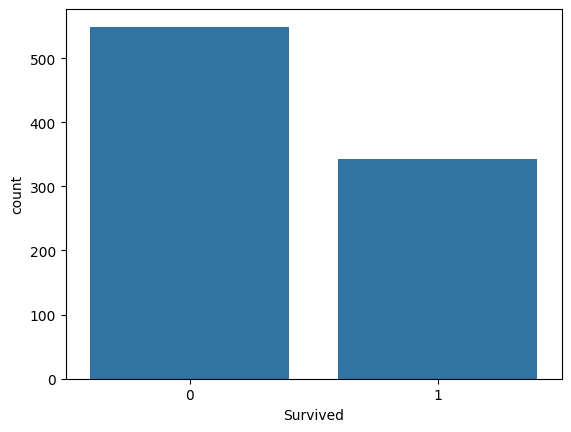

In [106]:
# ============================================================
# 생존자 비율
# ============================================================

sns.countplot(
    x="Survived",
    data=df
)

plt.show()

# 연령(Age) 분포 확인

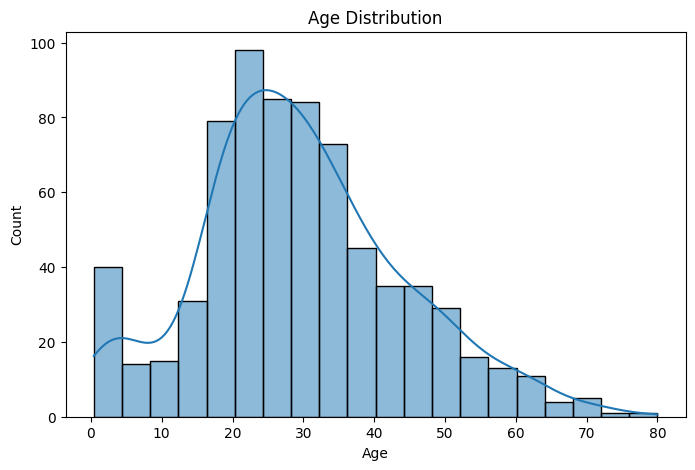

In [107]:
# ============================================================
# 히스토그램
# 어린 승객 많음

# 20~40세 구간 집중

# 완전한 정규분포는 아님
# ============================================================

plt.figure(figsize=(8,5))

sns.histplot(
    df["Age"],
    kde=True
)

plt.title("Age Distribution")

plt.show()

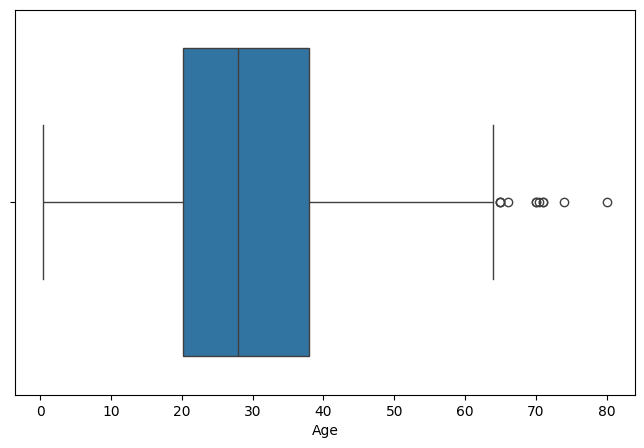

In [108]:
# ============================================================
# Boxplot
# ============================================================

plt.figure(figsize=(8,5))

sns.boxplot(
    x=df["Age"]
)

plt.show()

# IQR 이상치 탐지

In [109]:
# ============================================================
# IQR
# ============================================================

Q1 = df["Age"].quantile(0.25)

Q3 = df["Age"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR

upper = Q3 + 1.5 * IQR

print("하한:", lower)
print("상한:", upper)

하한: -6.6875
상한: 64.8125


In [110]:
# 이상치 확인

outliers = df[
    (df["Age"] < lower) |
    (df["Age"] > upper)
]

print(
    "이상치 개수:",
    len(outliers)
)

이상치 개수: 11


In [111]:
# ============================================================
# 왜도
# 왜도 > 0
# → 오른쪽 꼬리

# 왜도 < 0
# → 왼쪽 꼬리

# 왜도 ≒ 0
# → 정규분포에 가까움
# ============================================================

print(
    "왜도:",
    df["Fare"].skew()
)

왜도: 4.787316519674893


# 첨도(Kurtosis)

In [112]:
# ============================================================
# 첨도

# 첨도 > 3
# → 극단값 많음

# 첨도 < 3
# → 극단값 적음
# ============================================================

print(
    "첨도:",
    df["Fare"].kurt()
)

첨도: 33.39814088089868


# 상관관계 분석

In [113]:
# ============================================================
# 상관관계
# ============================================================

corr = df.corr(
    numeric_only=True
)

corr

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
PassengerId,1.000000,-0.005007,-0.035144,0.036847,-0.057527,-0.001652,0.012658
Survived,-0.005007,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
Pclass,-0.035144,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
Age,0.036847,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
SibSp,-0.057527,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
Parch,-0.001652,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
Fare,0.012658,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


# Heatmap

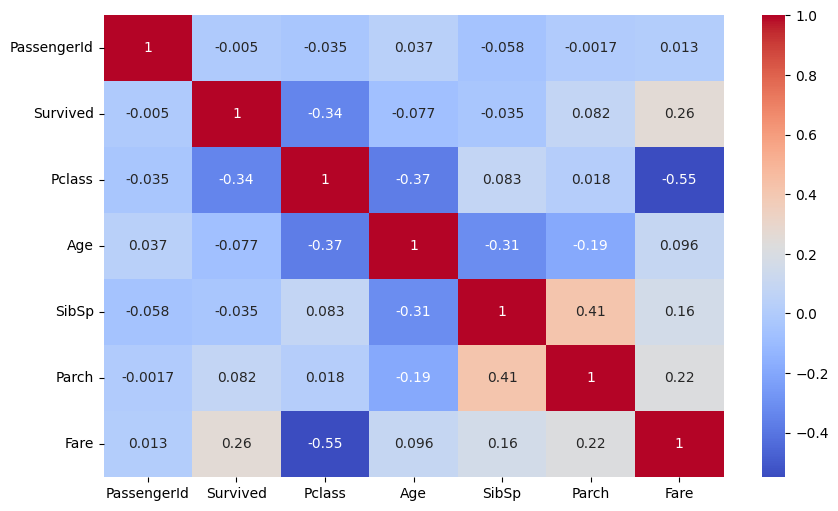

In [114]:
# ============================================================
# Heatmap

# Survived 와 Age, Fare, Pclass 의 관계 확인
# ============================================================

plt.figure(figsize=(10,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.show()

# 성별별 생존율

In [115]:
# ============================================================
# GroupBy
# ============================================================

df.groupby(
    "Sex"
)["Survived"].mean()

,Survived
Sex,
female,0.742038
male,0.188908


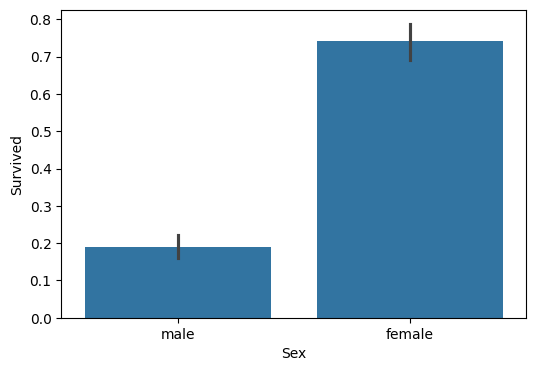

In [116]:
plt.figure(figsize=(6,4))

sns.barplot(
    data=df,
    x="Sex",
    y="Survived"
)

plt.show()

# 객실 등급별 생존율

In [117]:
# ============================================================
# Pclass
# ============================================================

df.groupby(
    "Pclass"
)["Survived"].mean()

,Survived
Pclass,
1,0.629630
2,0.472826
3,0.242363


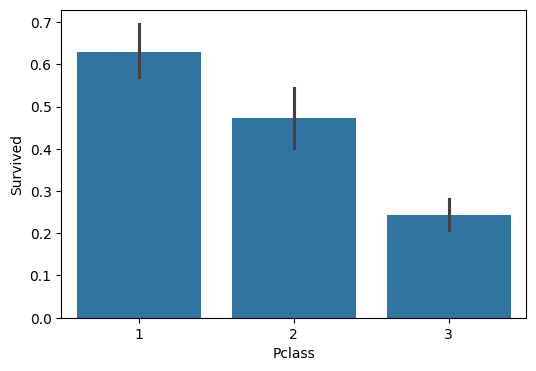

In [118]:
plt.figure(figsize=(6,4))

sns.barplot(
    data=df,
    x="Pclass",
    y="Survived"
)

plt.show()

# 정규성 검정

In [119]:
# ============================================================
# Normality Test
# ============================================================

from scipy.stats import normaltest

age = df["Age"].dropna()

stat, p = normaltest(age)

print("p-value:", p)

p-value: 0.00011709599657350757


In [120]:
if p >= 0.05:
    print("정규분포라고 볼 수 있음")
else:
    print("정규분포가 아님")

정규분포가 아님


# EDA 결과 정리

In [121]:
# ============================================================
# EDA 요약
# ============================================================

print("""
1. Age 결측치 존재
2. Cabin 결측치 매우 많음
3. Fare 분포 왜도 존재
4. 여성 생존율 높음
5. 1등석 생존율 높음
6. Age 정규성 완전 충족 안됨
7. 전처리 필요
""")


1. Age 결측치 존재
2. Cabin 결측치 매우 많음
3. Fare 분포 왜도 존재
4. 여성 생존율 높음
5. 1등석 생존율 높음
6. Age 정규성 완전 충족 안됨
7. 전처리 필요



# PART 3 : 데이터 전처리 (Data Preprocessing)
# 데이터 수집 → EDA → 전처리 → Feature Engineering → 머신러닝

In [122]:
# ============================================================
# Titanic 생존자 예측 프로젝트
# PART 3
# Data Preprocessing
# ============================================================

# ============================================================
# 전처리란?
# ============================================================
#
# 머신러닝 모델이 학습할 수 있도록
# 데이터를 정리하는 과정
#
# 주요 작업
#
# 1. 결측치 처리
# 2. 이상치 확인
# 3. 인코딩
# 4. Feature Engineering
# 5. 학습 데이터 생성
#
# ============================================================

# 데이터 복사 : 실무에서는 원본 데이터를 보존하는 습관이 중요하다.

In [123]:
# ============================================================
# 원본 데이터 보존
# ============================================================

df_pre = df.copy()

print(df_pre.shape)

(891, 12)


In [125]:
# sklearn의 전처리(preprocessing) 모듈에서
# LabelEncoder 클래스를 가져온다.
# 문자열 데이터를 숫자로 변환할 때 사용한다.
from sklearn.preprocessing import LabelEncoder

# LabelEncoder 객체 생성
# 앞으로 이 객체가 범주형 데이터를 학습(fit)하고
# 숫자로 변환(transform)하게 된다.
encoder = LabelEncoder()

# -----------------------------------------
# Sex 컬럼 인코딩
# -----------------------------------------

# df_pre["Sex"] 에 들어있는 고유값을 확인한 후
# (예: female, male)
# 자동으로 숫자를 부여하여 변환한다.
#
# 내부 동작:
# 1. fit()      -> 고유값 학습
# 2. transform() -> 숫자로 변환
#
# 예시
# female -> 0
# male   -> 1
#
# 변환된 결과를 다시 Sex 컬럼에 저장한다.
df_pre["Sex"] = encoder.fit_transform(df_pre["Sex"])

# -----------------------------------------
# Embarked 컬럼 인코딩
# -----------------------------------------

# Embarked 컬럼의 고유값을 학습한다.
#
# Titanic 데이터 예시
# C = Cherbourg
# Q = Queenstown
# S = Southampton
#
# LabelEncoder는 알파벳 순서로 번호를 부여한다.
#
# C -> 0
# Q -> 1
# S -> 2
#
# 변환된 결과를 다시 Embarked 컬럼에 저장한다.
df_pre["Embarked"] = encoder.fit_transform(df_pre["Embarked"])

# 결측치 재확인

In [126]:
# ============================================================
# 결측치 확인
# ============================================================

df_pre.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


# Age 결측치 처리

In [127]:
# ============================================================
# Age 결측치 처리
# ============================================================
#
# 평균(mean)
# 중앙값(median)
#
# 실무에서는 이상치 영향을 덜 받는
# 중앙값을 많이 사용
#
# ============================================================

df_pre["Age"] = df_pre["Age"].fillna(
    df_pre["Age"].median()
)

In [128]:
df_pre["Age"].isnull().sum()

np.int64(0)

# Embarked 결측치 처리

In [130]:
# ============================================================
# Embarked 결측치 처리
# ============================================================
#
# 범주형 변수
#
# 최빈값(mode) 사용
#
# ============================================================

df_pre["Embarked"] = df_pre["Embarked"].fillna(
    df_pre["Embarked"].mode()[0]
)

# Cabin 제거 : EDA에서 확인했듯이 Cabin 결측률이 매우 높다.

In [131]:
# ============================================================
# Cabin 제거
# ============================================================
#
# Cabin 결측률 약 77%
#
# 정보가 너무 부족하므로 제거
#
# ============================================================

df_pre = df_pre.drop(
    columns=["Cabin"]
)

# 결측치 최종 확인

In [132]:
# ============================================================
# 결측치 최종 확인
# ============================================================

df_pre.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


# 불필요 컬럼 제거 : 머신러닝에 도움이 거의 없는 컬럼 제거

In [133]:
# ============================================================
# 불필요 컬럼 제거
# ============================================================

drop_cols = [
    "PassengerId",
    "Name",
    "Ticket"
]

df_pre = df_pre.drop(
    columns=drop_cols
)

# 데이터 확인

In [134]:
print(df_pre.head())

   Survived  Pclass  Sex   Age  SibSp  Parch     Fare  Embarked
0         0       3    1  22.0      1      0   7.2500         2
1         1       1    0  38.0      1      0  71.2833         0
2         1       3    0  26.0      0      0   7.9250         2
3         1       1    0  35.0      1      0  53.1000         2
4         0       3    1  35.0      0      0   8.0500         2


# 범주형 변수 확인

In [135]:
# ============================================================
# 데이터 타입 확인
# Sex
# Embarked
# ============================================================

df_pre.dtypes

,0
Survived,int64
Pclass,int64
Sex,int64
Age,float64
SibSp,int64
Parch,int64
Fare,float64
Embarked,int64


# Label Encoding : 머신러닝은 문자열을 학습할 수 없다. 숫자로 변환해야 한다.

In [136]:
# ============================================================
# Label Encoding
# ============================================================

from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

In [137]:
# ============================================================
# Label Encoding
# female → 0
# male   → 1
# ============================================================

from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

# Embarked 인코딩

In [138]:
# C → 0
# Q → 1
# S → 2

df_pre["Embarked"] = encoder.fit_transform(
    df_pre["Embarked"]
)

# Feature Engineering : 실무 핵심 단계

# 새로운 변수를 만든다.

In [139]:
# 가족 수 생성
# ============================================================
# FamilySize 생성
# ============================================================
#
# 본인 + 형제배우자 + 부모자녀
#
# ============================================================

df_pre["FamilySize"] = (
    df_pre["SibSp"]
    + df_pre["Parch"]
    + 1
)

In [140]:
# 혼자 탑승 여부
# ============================================================
# IsAlone 생성
# ============================================================

df_pre["IsAlone"] = (
    df_pre["FamilySize"] == 1
).astype(int)

In [141]:
# 확인
df_pre[
    ["SibSp",
     "Parch",
     "FamilySize",
     "IsAlone"]
].head()

# Feature Engineering 이유

# 예를 들어

# SibSp = 2
# Parch = 1   보다

# FamilySize = 4 가 머신러닝 입장에서는 더 의미 있는 정보일 수 있다.

,SibSp,Parch,FamilySize,IsAlone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1


In [142]:
# 최종 데이터 확인
df_pre.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    891 non-null    int64  
 1   Pclass      891 non-null    int64  
 2   Sex         891 non-null    int64  
 3   Age         891 non-null    float64
 4   SibSp       891 non-null    int64  
 5   Parch       891 non-null    int64  
 6   Fare        891 non-null    float64
 7   Embarked    891 non-null    int64  
 8   FamilySize  891 non-null    int64  
 9   IsAlone     891 non-null    int64  
dtypes: float64(2), int64(8)
memory usage: 69.7 KB


# 머신러닝 입력 데이터 준비

In [143]:

# ============================================================
# Target
# ============================================================

y = df_pre["Survived"]


# ============================================================
# Feature
# ============================================================

X = df_pre.drop(
    columns=["Survived"]
)

# 확인

print(X.shape)
print(y.shape)

(891, 9)
(891,)


# Train / Test 분리

In [144]:
# ============================================================
# Train Test Split
# ============================================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [145]:
print(X_train.shape)
print(X_test.shape)

(712, 9)
(179, 9)


In [146]:
# PART 3 결과 요약
print("""
전처리 완료

1. Age 결측치 처리
2. Embarked 결측치 처리
3. Cabin 제거
4. 불필요 컬럼 제거
5. Label Encoding
6. FamilySize 생성
7. IsAlone 생성
8. Train/Test 분리 완료
""")


전처리 완료

1. Age 결측치 처리
2. Embarked 결측치 처리
3. Cabin 제거
4. 불필요 컬럼 제거
5. Label Encoding
6. FamilySize 생성
7. IsAlone 생성
8. Train/Test 분리 완료



# PART 4 : 머신러닝 모델 학습 및 평가

In [147]:
# ============================================================
# Titanic 생존자 예측 프로젝트
# PART 4
# Machine Learning
# ============================================================

# ============================================================
# 머신러닝 단계
# ============================================================
#
# 지금까지
#
# 데이터 수집
# → EDA
# → 전처리
#
# 를 완료했다.
#
# 이제 머신러닝 모델을 학습하여
# 생존 여부를 예측한다.
#
# ============================================================

In [148]:
# ============================================================
# 머신러닝 라이브러리
# ============================================================

# sklearn.metrics 모듈에서
# 모델 성능 평가에 사용하는 다양한 함수들을 가져온다.
from sklearn.metrics import (

    # Accuracy(정확도)
    # 전체 예측 중 맞춘 비율
    # (TP + TN) / 전체 데이터
    accuracy_score,

    # Precision(정밀도)
    # 모델이 Positive라고 예측한 것 중
    # 실제 Positive 비율
    # TP / (TP + FP)
    precision_score,

    # Recall(재현율)
    # 실제 Positive 중에서
    # 모델이 올바르게 찾아낸 비율
    # TP / (TP + FN)
    recall_score,

    # F1 Score
    # Precision과 Recall의 조화평균
    # 클래스 불균형 데이터에서 자주 사용
    f1_score,

    # Classification Report
    # Accuracy, Precision, Recall, F1 Score 등을
    # 한 번에 출력하는 보고서 함수
    classification_report,

    # Confusion Matrix
    # TP, TN, FP, FN을 표 형태로 출력
    # 모델이 어디서 틀렸는지 확인 가능
    confusion_matrix
)

In [163]:
# ============================================================
# Logistic Regression : 가장 기본
# ============================================================

from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [152]:
# ============================================================
# 모델 학습
# ============================================================

log_model.fit(
    X_train,
    y_train
)

LogisticRegression(max_iter=1000, random_state=42)

In [153]:
# ============================================================
# 예측
# ============================================================

log_pred = log_model.predict(
    X_test
)

In [154]:
# 정확도 평가
# ============================================================
# Accuracy
# ============================================================

log_acc = accuracy_score(
    y_test,
    log_pred
)

print(
    "Logistic Accuracy:",
    round(log_acc, 4)
)

Logistic Accuracy: 0.7989


In [156]:
# ============================================================
# Precision
# ============================================================

log_precision = precision_score(
    y_test,
    log_pred
)

print(
    "Precision:",
    round(log_precision, 4)
)

Precision: 0.7714


In [157]:
# ============================================================
# Recall
# ============================================================

log_recall = recall_score(
    y_test,
    log_pred
)

print(
    "Recall:",
    round(log_recall, 4)
)

Recall: 0.7297


In [158]:
# ============================================================
# F1 Score
# ============================================================

log_f1 = f1_score(
    y_test,
    log_pred
)

print(
    "F1 Score:",
    round(log_f1, 4)
)

F1 Score: 0.75


In [159]:
# ============================================================
# Classification Report
# precision → 예측이 얼마나 정확한가

# recall → 실제 정답을 얼마나 찾았는가

# f1-score → precision + recall 종합 점수
# ============================================================

print(
    classification_report(
        y_test,
        log_pred
    )
)

              precision    recall  f1-score   support

           0       0.82      0.85      0.83       105
           1       0.77      0.73      0.75        74

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



In [160]:
# ============================================================
# Confusion Matrix (오차 행렬)
# ============================================================
#
# 머신러닝 분류 모델 평가 방법
#
# 단순 Accuracy(정확도)만 보면
# 모델이 실제로 어떤 예측을 잘했고
# 어떤 예측을 틀렸는지 알 수 없다.
#
# Confusion Matrix는
# 실제값과 예측값을 비교하여
# 상세한 성능을 확인할 수 있는 표이다.
#
#                예측
#             사망   생존

# 실제 사망     90    15

# 실제 생존     20    54
# ============================================================

cm = confusion_matrix(
    y_test,
    log_pred
)

print(cm)

[[89 16]
 [20 54]]


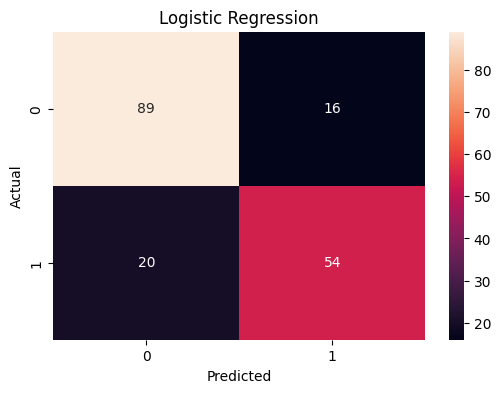

In [161]:
# ============================================================
# Confusion Matrix 시각화
# ============================================================
#
# heatmap을 사용하면
# 모델이 어느 부분에서 많이 틀렸는지
# 한눈에 확인할 수 있다.
#
# annot=True
# → 숫자 표시
#
# fmt="d"
# → 정수 형태 출력
#
# ============================================================

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title(
    "Logistic Regression"
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [164]:
# ============================================================
# Random Forest
# ============================================================
#
# 실무에서 가장 많이 사용하는
# 머신러닝 알고리즘 중 하나
#
# 여러 개의 의사결정나무(Decision Tree)를
# 생성한 후
#
# 투표(Voting)를 통해
# 최종 결과를 결정한다.
#
# 장점
#
# - 높은 성능
# - 과적합 감소
# - 변수 중요도 제공
# - 전처리 부담 적음
#
# ============================================================

from sklearn.ensemble import RandomForestClassifier

# Random Forest 분류 모델 생성
# 여러 개의 의사결정나무(Decision Tree)를 만들어
# 다수결 투표 방식으로 최종 예측을 수행하는 앙상블 모델

rf_model = RandomForestClassifier(

    # 생성할 의사결정나무(Tree)의 개수
    # 여기서는 200개의 트리를 생성
    # 일반적으로 트리 개수가 많을수록 성능은 좋아질 수 있으나
    # 학습 시간과 메모리 사용량도 증가한다.
    n_estimators=200,

    # 난수 시드(Random Seed) 고정
    # 데이터를 무작위로 샘플링하는 과정에서
    # 매번 동일한 결과를 얻기 위해 사용
    # 실무 및 프로젝트에서는 재현성(Reproducibility)을 위해
    # 반드시 설정하는 것이 좋다.
    random_state=42
)

In [166]:
# ============================================================
# 모델 학습
# ============================================================
#
# fit()
#
# 학습 데이터를 사용하여
# 패턴을 찾는 과정
#
# ============================================================

rf_model.fit(
    X_train,
    y_train
)

RandomForestClassifier(n_estimators=200, random_state=42)

In [167]:
# ============================================================
# 예측
# ============================================================
#
# 학습 완료된 모델을 이용하여
# 테스트 데이터의 생존 여부 예측
#
# ============================================================

rf_pred = rf_model.predict(
    X_test
)

In [168]:
# ============================================================
# Accuracy
# ============================================================
#
# 전체 예측 중
# 맞춘 비율
#
# Accuracy =
#
# 맞춘 개수
# ----------
# 전체 개수
#
# ============================================================

rf_acc = accuracy_score(
    y_test,
    rf_pred
)

print(
    "Random Forest Accuracy:",
    round(rf_acc, 4)
)

Random Forest Accuracy: 0.8156


In [169]:
# ============================================================
# Precision
# ============================================================
#
# 생존이라고 예측한 사람 중
# 실제 생존자의 비율
#
# Precision이 높을수록
# 잘못된 생존 예측(False Positive)이 적다.
#
# ============================================================

print(
    "Precision:",
    round(
        precision_score(
            y_test,
            rf_pred
        ),
        4
    )
)

Precision: 0.7887


In [170]:
# ============================================================
# Recall
# ============================================================
#
# 실제 생존자 중
# 모델이 찾아낸 비율
#
# Recall이 높을수록
# 실제 생존자를 놓치는 경우(False Negative)가 적다.
#
# ============================================================

print(
    "Recall:",
    round(
        recall_score(
            y_test,
            rf_pred
        ),
        4
    )
)

Recall: 0.7568


In [171]:
# ============================================================
# F1 Score
# ============================================================
#
# Precision + Recall의
# 균형 점수
#
# 분류 문제에서
# Accuracy보다 더 중요한 경우가 많다.
#
# ============================================================

print(
    "F1:",
    round(
        f1_score(
            y_test,
            rf_pred
        ),
        4
    )
)

F1: 0.7724


In [172]:
# ============================================================
# Classification Report
# ============================================================
#
# Accuracy
# Precision
# Recall
# F1-score
#
# 를 한 번에 확인
#
# 실무에서 가장 자주 사용하는 평가표
#
# ============================================================

print(
    classification_report(
        y_test,
        rf_pred
    )
)

              precision    recall  f1-score   support

           0       0.83      0.86      0.85       105
           1       0.79      0.76      0.77        74

    accuracy                           0.82       179
   macro avg       0.81      0.81      0.81       179
weighted avg       0.81      0.82      0.82       179



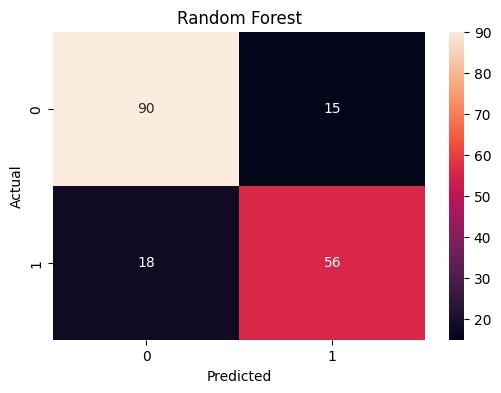

In [173]:
# ============================================================
# Random Forest 오차 행렬
# ============================================================
#
# Logistic Regression과 비교하여
# 어떤 모델이 더 좋은지 판단
#
# ============================================================

rf_cm = confusion_matrix(
    y_test,
    rf_pred
)

plt.figure(figsize=(6,4))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d"
)

plt.title(
    "Random Forest"
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [174]:
# ============================================================
# 모델 비교
# ============================================================
#
# 여러 모델을 학습한 후
# 결과를 표로 정리
#
# 실무에서는
#
# Accuracy
# Precision
# Recall
# F1
#
# 을 모두 비교한다.
#
# ============================================================

result = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        log_acc,
        rf_acc
    ]
})

print(result)

                 Model  Accuracy
0  Logistic Regression  0.798883
1        Random Forest  0.815642


In [175]:
# ============================================================
# Feature Importance
# ============================================================
#
# Random Forest의 대표 장점
#
# 어떤 변수가
# 생존 여부 예측에 가장 큰 영향을 주는지
# 수치로 확인 가능
#
# 값이 클수록 중요도가 높음
#
# ============================================================

# Random Forest 모델이 계산한 변수 중요도(Feature Importance)를
# 보기 쉽게 DataFrame 형태로 생성

importance = pd.DataFrame({

    # Feature 컬럼 생성
    # X 데이터셋의 컬럼명을 가져온다.
    # 예:
    # Pclass
    # Sex
    # Age
    # Fare
    # Embarked
    "Feature": X.columns,

    # Importance 컬럼 생성
    # Random Forest가 학습하면서 계산한
    # 각 변수의 중요도 값을 가져온다.
    #
    # 값이 클수록 예측에 큰 영향을 준 변수
    # 값이 작을수록 예측에 거의 영향을 주지 않은 변수
    "Importance": rf_model.feature_importances_
})

In [176]:
# ============================================================
# 중요도 내림차순 정렬
# ============================================================
#
# 가장 중요한 변수부터 확인
#
# ascending=False
#
# 큰 값 → 작은 값
#
# ============================================================

importance = importance.sort_values(
    "Importance",
    ascending=False
)

importance

,Feature,Importance
1,Sex,0.281012
5,Fare,0.255386
2,Age,0.245123
0,Pclass,0.085081
7,FamilySize,0.045722
6,Embarked,0.031923
3,SibSp,0.026883
4,Parch,0.019670
8,IsAlone,0.009201


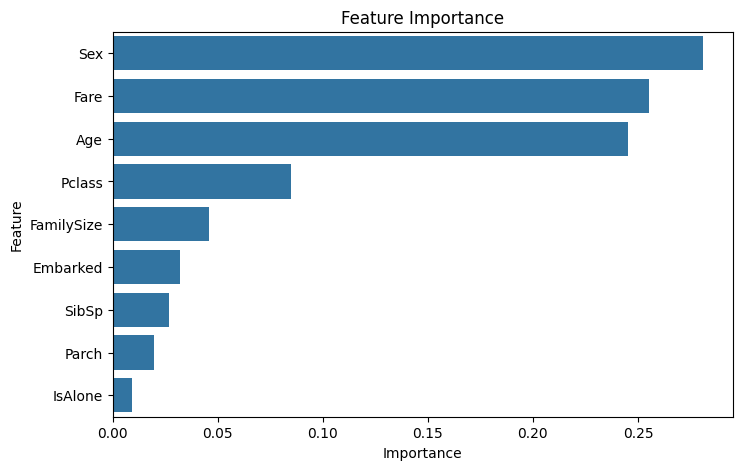

In [177]:
# ============================================================
# Feature Importance 시각화
# ============================================================
#
# 막대그래프로 표현
#
# 막대가 길수록
# 모델에 큰 영향을 준 변수
#
# ============================================================

plt.figure(figsize=(8,5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title(
    "Feature Importance"
)

plt.show()

In [178]:
# ============================================================
# 결과 해석
# ============================================================
#
# 일반적으로 Titanic 데이터에서는
#
# Sex
# Fare
# Age
# Pclass
# FamilySize
#
# 가 높은 중요도를 가진다.
#

# 데이터 분석 관점
# Feature Importance는

# "무슨 변수가 중요한가?" 를 알려준다.

# 하지만 "왜 중요한가?" 까지 설명하지는 못한다.

# 그래서 EDA 결과와 함께 해석해야 한다.
# ============================================================